In [7]:
image = cv2.imread("image1.jpg", cv2.IMREAD_GRAYSCALE)
image_scaled = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_LINEAR)
cv2.imwrite('image1_scaled.jpg', image_scaled)

image_illum = cv2.convertScaleAbs(image, alpha=0.5, beta=-50)
cv2.imwrite('image1_illum.jpg', image_illum)

(h, w) = image.shape[:2]
center = (w // 2, h // 2)
M = cv2.getRotationMatrix2D(center, 90, 1.0) 
image_rotated = cv2.warpAffine(image, M, (w, h))
cv2.imwrite('image1_rotated.jpg', image_rotated)

True

--- Running Comparison for Algorithm: AKAZE ---
Image 1: image1.jpg
Image 2: image1_illum.jpg
Detected 11978 keypoints in img1, 161 keypoints in img2
Found 144 good matches out of 11978 potential pairs (Ratio=0.75)


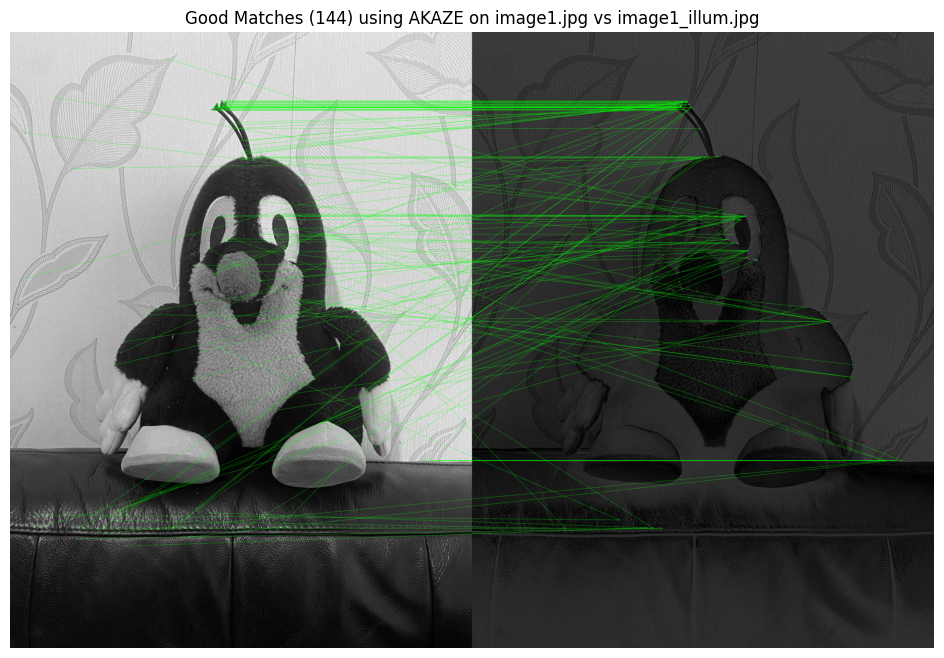

--- Comparison Complete ---


In [25]:
# Import necessary libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time # Optional: for timing

# --- Configuration ---
# <<< MODIFY THESE PATHS >>>
IMG1_PATH = 'image1.jpg' # Path to the first image (your base image)
IMG2_PATH = 'image1_illum.jpg' # Path to the second image (e.g., rotated, scaled, viewpoint change)

# <<< CHOOSE THE ALGORITHM HERE >>>
ALGORITHM = 'AKAZE' # Options: 'ORB', 'SIFT', 'AKAZE' (Add 'BRISK' etc. if desired)

LOWE_RATIO = 0.75 # Ratio threshold for filtering good matches (0.7 to 0.8 is common)
# ---------------------

# --- Load Images ---
img1 = cv2.imread(IMG1_PATH, cv2.IMREAD_GRAYSCALE) # Load as grayscale
img2 = cv2.imread(IMG2_PATH, cv2.IMREAD_GRAYSCALE)

if img1 is None:
    print(f"Error loading image 1: Check path '{IMG1_PATH}'")
    exit()
if img2 is None:
    print(f"Error loading image 2: Check path '{IMG2_PATH}'")
    exit()

# --- Initialize Algorithm ---
detector = None
matcher_norm = None

print(f"--- Running Comparison for Algorithm: {ALGORITHM} ---")
print(f"Image 1: {IMG1_PATH}")
print(f"Image 2: {IMG2_PATH}")


try:
    if ALGORITHM == 'ORB':
        detector = cv2.ORB_create(nfeatures=1000) # Adjust nfeatures if needed
        matcher_norm = cv2.NORM_HAMMING # Hamming distance for binary descriptors
    elif ALGORITHM == 'SIFT':
        # SIFT might require the opencv-contrib-python package
        detector = cv2.SIFT_create()
        matcher_norm = cv2.NORM_L2 # L2 distance (Euclidean) for float descriptors
    elif ALGORITHM == 'AKAZE':
        detector = cv2.AKAZE_create()
        matcher_norm = cv2.NORM_HAMMING # Hamming distance for binary descriptors
    # Add elif blocks here for other algorithms like BRISK if needed
    # elif ALGORITHM == 'BRISK':
    #    detector = cv2.BRISK_create()
    #    matcher_norm = cv2.NORM_HAMMING
    else:
        print(f"Error: Unknown or unsupported algorithm '{ALGORITHM}'")
        exit()
except AttributeError as e:
     print(f"Error initializing {ALGORITHM}: {e}")
     print("Ensure OpenCV and potentially opencv-contrib-python are installed correctly.")
     print("Try: pip install opencv-python opencv-contrib-python")
     exit()

# --- Detect Keypoints and Compute Descriptors ---
start_time = time.time() # Optional timing

# Find the keypoints and compute descriptors
kp1, des1 = detector.detectAndCompute(img1, None)
kp2, des2 = detector.detectAndCompute(img2, None)

detect_compute_time = time.time() - start_time # Optional timing

# --- Check if Descriptors Found ---
if des1 is None or len(des1) == 0:
    print(f"Warning: No descriptors found for Image 1 using {ALGORITHM}.")
    # Optionally display image 1 if no keypoints found
    # plt.imshow(img1, cmap='gray'); plt.title(f"{ALGORITHM} - No Keypoints in Image 1"); plt.show()
    exit()
if des2 is None or len(des2) == 0:
    print(f"Warning: No descriptors found for Image 2 using {ALGORITHM}.")
    # Optionally display image 2 if no keypoints found
    # plt.imshow(img2, cmap='gray'); plt.title(f"{ALGORITHM} - No Keypoints in Image 2"); plt.show()
    exit()

print(f"Detected {len(kp1)} keypoints in img1, {len(kp2)} keypoints in img2")
# print(f"Detection & Computation time: {detect_compute_time:.4f} seconds") # Optional timing uncomment if desired

# --- Match Descriptors ---
start_time = time.time() # Optional timing

# Create BFMatcher (Brute Force Matcher) object
# Use crossCheck=False to enable k-NN matching needed for ratio test
bf = cv2.BFMatcher(matcher_norm, crossCheck=False)

# Find the k best matches for each descriptor (k=2 for ratio test)
# Ensure des1 and des2 are not empty before matching
raw_matches = bf.knnMatch(des1, des2, k=2)

match_time = time.time() - start_time # Optional timing
# print(f"Matching time: {match_time:.4f} seconds") # Optional timing uncomment if desired

# --- Apply Lowe's Ratio Test ---
good_matches = []
potential_match_count = 0
for match_pair in raw_matches:
    # Ensure the pair contains two matches (needed for ratio test)
    if len(match_pair) == 2:
        m, n = match_pair
        potential_match_count += 1
        # Compare distances: m is the best match, n is the second best
        if m.distance < LOWE_RATIO * n.distance:
            good_matches.append(m) # Keep the best match 'm'

print(f"Found {len(good_matches)} good matches out of {potential_match_count} potential pairs (Ratio={LOWE_RATIO})")

# --- Draw Matches ---
# Need to convert grayscale images back to BGR for color drawing
img1_bgr = cv2.cvtColor(img1, cv2.COLOR_GRAY2BGR)
img2_bgr = cv2.cvtColor(img2, cv2.COLOR_GRAY2BGR)

# Draw only the good matches
img_matches = cv2.drawMatches(img1_bgr, kp1, img2_bgr, kp2, good_matches, None,
                              matchColor=(0, 255, 0), # Green lines for good matches
                              singlePointColor=None, # Don't draw single points
                              flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS) # Only draw matches

# --- Display Results ---
plt.figure(figsize=(16, 8)) # Adjust figure size as needed
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB)) # Convert BGR to RGB for Matplotlib
plt.title(f'Good Matches ({len(good_matches)}) using {ALGORITHM} on {IMG1_PATH} vs {IMG2_PATH}')
plt.axis('off') # Hide axes
plt.show()

print("--- Comparison Complete ---")